# Target Construction

**Project:** Predicting Performance Trajectories of Women Micro-Enterprises: An Early Warning Framework

This notebook constructs the research outcome variable:

- **High**
- **Moderate**
- **Low / At-Risk**

The target is created only after checking that the financial measurement periods are comparable across cohorts.

### Target definition

**High**
- S1 > S0
- S2 ≥ S1
- S3 ≥ S2

**Moderate**
- S3 ≥ S0
- but does not satisfy the High criteria

**Low / At-Risk**
- S3 < S0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/24088950_MAI_Research')
DATA_PATH = PROJECT_DIR / 'Ibupreneur_Academy_Microenterprise_Performance_Raw_Dataset_2025_2026.xlsm'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
RELATIONSHIP_PATH = OUTPUT_DIR / 'relationship_base.csv'

print('Project folder:', PROJECT_DIR)
print('Raw dataset:', DATA_PATH)
print('Output folder:', OUTPUT_DIR)
print('Relationship dataset:', RELATIONSHIP_PATH)
print('Raw dataset exists:', DATA_PATH.exists())
print('Relationship dataset exists:', RELATIONSHIP_PATH.exists())

Mounted at /content/drive
Project folder: /content/drive/MyDrive/24088950_MAI_Research
Raw dataset: /content/drive/MyDrive/24088950_MAI_Research/Ibupreneur_Academy_Microenterprise_Performance_Raw_Dataset_2025_2026.xlsm
Output folder: /content/drive/MyDrive/24088950_MAI_Research/outputs
Relationship dataset: /content/drive/MyDrive/24088950_MAI_Research/outputs/relationship_base.csv
Raw dataset exists: True
Relationship dataset exists: True


## 1. Load Connected Data

This notebook uses the raw Master dataset for the Finance sheet and `relationship_base.csv` from Notebook 01.

In [2]:
# 1. Load data

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Raw dataset not found: {DATA_PATH}')

if not RELATIONSHIP_PATH.exists():
    raise FileNotFoundError('relationship_base.csv was not found. Run Notebook 01 first and save the output to the outputs folder.')

relationship_base = pd.read_csv(RELATIONSHIP_PATH)
finance = pd.read_excel(DATA_PATH, sheet_name='Finance Sales Profit', header=3)
finance = finance[finance['Participant ID'].notna()].copy()

print('relationship_base shape:', relationship_base.shape)
print('finance shape:', finance.shape)
display(finance.head())

relationship_base shape: (201, 80)
finance shape: (196, 24)


,Cohort ID,Funder/Program,Year,Participant ID,Full Name [REMOVED - PII],Months Tracked,Sales Before Program,Sales Month 1,Sales Month 2,Sales Month 3,...,Profit Before Program,Profit Month 1,Profit Month 2,Profit Month 3,Total Profit,Avg % Increase Profit per Month,Total Cost for 3 Months,Funding Eligibity,Total Seed Funding Received,Total Bonus Payout
0,MIB-2025-C1,MIB,2025,2025_IBU-ACADEMY-MIB-C1-01,NaN,Aug - Oct,8800,13750,15000,20508,...,15000,4440,4800.0,7658,16898.00,-0.009167,32360,1.0,2000.0,150.0
1,MIB-2025-C1,MIB,2025,2025_IBU-ACADEMY-MIB-C1-02,NaN,Aug - Oct,800,3000,4200,5300,...,360,1500,2100.0,2650,6250.00,1.276190,9000,1.0,2000.0,150.0
2,MIB-2025-C1,MIB,2025,2025_IBU-ACADEMY-MIB-C1-03,NaN,Aug - Oct,3000,NaN,NaN,NaN,...,2300,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0
3,MIB-2025-C1,MIB,2025,2025_IBU-ACADEMY-MIB-C1-04,NaN,Aug - Oct,2800,7600,3900,4600,...,2400,2672.4,2895.1,3414.73,8982.23,0.125440,3117.77,1.0,2000.0,150.0
4,MIB-2025-C1,MIB,2025,2025_IBU-ACADEMY-MIB-C1-05,NaN,Aug - Oct,2300,9960,8150,10580,...,1500,3416,3210.0,4500,11126.00,0.539633,17429,1.0,2000.0,150.0


## 2. Finance Structure and Data-Type Check

In [3]:
# 2. Check finance columns

print('Finance columns:')
for column in finance.columns:
    print('-', column)

Finance columns:
- Cohort ID
- Funder/Program
- Year
- Participant ID
- Full Name [REMOVED - PII]
- Months Tracked
- Sales Before Program
- Sales Month 1
- Sales Month 2
- Sales Month 3
- Total Sales Revenue
- Average Monthly Sales
- Avg % Increase Sales per Month
- Sales Growth Rate %
- Profit Before Program
- Profit Month 1
- Profit Month 2
- Profit Month 3
- Total Profit
- Avg % Increase Profit per Month
- Total Cost for 3 Months
- Funding Eligibity
- Total Seed Funding Received
- Total Bonus Payout


In [4]:
# 2.1 Convert sales variables to numeric

sales_columns = ['Sales Before Program','Sales Month 1','Sales Month 2','Sales Month 3']

def parse_numeric(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.number)):
        return float(x)
    text = str(x).strip().upper().replace('RM','').replace(',','').replace('%','')
    if text in ['', 'N/A', 'NA', '-', 'NONE', 'NAN']:
        return np.nan
    return pd.to_numeric(text, errors='coerce')

for column in sales_columns:
    finance[column] = finance[column].map(parse_numeric)

display(finance[['Cohort ID','Participant ID'] + sales_columns].head())

,Cohort ID,Participant ID,Sales Before Program,Sales Month 1,Sales Month 2,Sales Month 3
0,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-01,8800.0,13750.0,15000.0,20508.0
1,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-02,800.0,3000.0,4200.0,5300.0
2,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-03,3000.0,NaN,NaN,NaN
3,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-04,2800.0,7600.0,3900.0,4600.0
4,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-05,2300.0,9960.0,8150.0,10580.0


## 3. Financial Outcome Availability by Cohort

In [5]:
# 3. Financial outcome availability

finance['Complete S0-S3'] = finance[sales_columns].notna().all(axis=1)

target_coverage = (
    finance.groupby(['Cohort ID','Funder/Program','Year'], dropna=False)
    .agg(
        Participants=('Participant ID','nunique'),
        S0_Available=('Sales Before Program', lambda x: x.notna().sum()),
        S1_Available=('Sales Month 1', lambda x: x.notna().sum()),
        S2_Available=('Sales Month 2', lambda x: x.notna().sum()),
        S3_Available=('Sales Month 3', lambda x: x.notna().sum()),
        Complete_S0_S3=('Complete S0-S3','sum')
    ).reset_index()
)

target_coverage['Complete S0-S3 %'] = (target_coverage['Complete_S0_S3'] / target_coverage['Participants'] * 100).round(1)
display(target_coverage)

,Cohort ID,Funder/Program,Year,Participants,S0_Available,S1_Available,S2_Available,S3_Available,Complete_S0_S3,Complete S0-S3 %
0,AIB-2026-MEKAR-C1,AIB,2026,28,28,27,26,26,26,92.9
1,CIMB-2026-MH-C1,CIMB,2026,28,27,26,27,27,25,89.3
2,MBSB-2025-C1,MBSB,2025,20,20,18,18,19,18,90.0
3,MIB-2025-C1,MIB,2025,33,31,27,28,28,27,81.8
4,MIB-2025-C2,MIB,2025,34,32,32,33,33,30,88.2
5,MIB-2025-C3,MIB,2025,28,25,28,28,27,24,85.7
6,UNDP-2026-C1,UNDP,2026,25,25,23,23,23,23,92.0


In [6]:
# 3.1 Percentage availability for S0-S3

tracking_percentage = target_coverage[['Cohort ID','Participants','S0_Available','S1_Available','S2_Available','S3_Available']].copy()
for column in ['S0_Available','S1_Available','S2_Available','S3_Available']:
    tracking_percentage[column] = (tracking_percentage[column] / tracking_percentage['Participants'] * 100).round(1)
display(tracking_percentage)

,Cohort ID,Participants,S0_Available,S1_Available,S2_Available,S3_Available
0,AIB-2026-MEKAR-C1,28,100.0,96.4,92.9,92.9
1,CIMB-2026-MH-C1,28,96.4,92.9,96.4,96.4
2,MBSB-2025-C1,20,100.0,90.0,90.0,95.0
3,MIB-2025-C1,33,93.9,81.8,84.8,84.8
4,MIB-2025-C2,34,94.1,94.1,97.1,97.1
5,MIB-2025-C3,28,89.3,100.0,100.0,96.4
6,UNDP-2026-C1,25,100.0,92.0,92.0,92.0


## 4. Data-Quality Checks Before Target Construction

These checks identify records that could make the target invalid or misleading. A statistical outlier is not automatically an error.

In [7]:
# 4. Duplicate finance participant IDs

finance_duplicate_ids = finance['Participant ID'].value_counts()
finance_duplicate_ids = finance_duplicate_ids[finance_duplicate_ids > 1]

if len(finance_duplicate_ids) == 0:
    print('No duplicate Participant IDs in Finance.')
else:
    display(finance_duplicate_ids.rename('Rows').reset_index().rename(columns={'index':'Participant ID'}))

No duplicate Participant IDs in Finance.


In [8]:
# 4.1 Negative sales values

negative_sales = finance[(finance[sales_columns] < 0).any(axis=1)][['Cohort ID','Participant ID'] + sales_columns]
print('Records with negative sales:', len(negative_sales))
if len(negative_sales):
    display(negative_sales)

Records with negative sales: 0


In [9]:
# 4.2 Zero sales values

zero_sales_summary = pd.DataFrame({
    'Variable': sales_columns,
    'Zero n': [(finance[column] == 0).sum() for column in sales_columns],
    'Available n': [finance[column].notna().sum() for column in sales_columns]
})
zero_sales_summary['Zero % of available'] = (zero_sales_summary['Zero n'] / zero_sales_summary['Available n'] * 100).round(1)
display(zero_sales_summary)

,Variable,Zero n,Available n,Zero % of available
0,Sales Before Program,7,188,3.7
1,Sales Month 1,0,181,0.0
2,Sales Month 2,1,183,0.5
3,Sales Month 3,1,183,0.5


## 5. Cohort Measurement-Timing Review

For each cohort, verify what `Sales Month 1`, `Sales Month 2`, and `Sales Month 3` actually represent. Do not mark a cohort as eligible only because S0–S3 are complete.

In [10]:
# 5. Create timing review template

cohort_timing_review = (
    finance[['Cohort ID','Funder/Program','Year']]
    .drop_duplicates()
    .sort_values(['Year','Cohort ID'])
    .reset_index(drop=True)
)
cohort_timing_review['S0 Meaning'] = 'Before Programme'
cohort_timing_review['S1-S3 Meaning'] = 'VERIFY'
cohort_timing_review['Comparable for Target'] = 'VERIFY'
cohort_timing_review['Reason'] = ''
display(cohort_timing_review)

,Cohort ID,Funder/Program,Year,S0 Meaning,S1-S3 Meaning,Comparable for Target,Reason
0,MBSB-2025-C1,MBSB,2025,Before Programme,VERIFY,VERIFY,
1,MIB-2025-C1,MIB,2025,Before Programme,VERIFY,VERIFY,
2,MIB-2025-C2,MIB,2025,Before Programme,VERIFY,VERIFY,
3,MIB-2025-C3,MIB,2025,Before Programme,VERIFY,VERIFY,
4,AIB-2026-MEKAR-C1,AIB,2026,Before Programme,VERIFY,VERIFY,
5,CIMB-2026-MH-C1,CIMB,2026,Before Programme,VERIFY,VERIFY,
6,UNDP-2026-C1,UNDP,2026,Before Programme,VERIFY,VERIFY,


In [11]:
# 5.1 Save timing review template

TIMING_REVIEW_PATH = OUTPUT_DIR / 'cohort_financial_timing_review.csv'
cohort_timing_review.to_csv(TIMING_REVIEW_PATH, index=False)
print('Saved timing review template:', TIMING_REVIEW_PATH)

Saved timing review template: /content/drive/MyDrive/24088950_MAI_Research/outputs/cohort_financial_timing_review.csv


## 6. Define Eligible Cohorts

Edit the list below **only after verifying the financial measurement timing**.

In [16]:
# 6. Define eligible cohorts

eligible_cohorts = [
    'MIB-2025-C1',
    'MIB-2025-C2',
    'MIB-2025-C3',
    'MBSB-2025-C1',
    'AIB-2026-MEKAR-C1',
    'UNDP-2026-C1',
    'CIMB-2026-MH-C1'
]

print('Eligible cohorts selected:')
print(eligible_cohorts)

if len(eligible_cohorts) == 0:
    print('''No cohorts selected yet. Complete the timing review before continuing.''')

Eligible cohorts selected:
['MIB-2025-C1', 'MIB-2025-C2', 'MIB-2025-C3', 'MBSB-2025-C1', 'AIB-2026-MEKAR-C1', 'UNDP-2026-C1', 'CIMB-2026-MH-C1']


In [17]:
# 6.1 Validate selected cohort names

available_cohorts = sorted(finance['Cohort ID'].dropna().astype(str).unique())
invalid_cohorts = [cohort for cohort in eligible_cohorts if cohort not in available_cohorts]

print('Available cohorts:')
for cohort in available_cohorts:
    print('-', cohort)

if invalid_cohorts:
    raise ValueError(f'These eligible_cohorts were not found in Finance: {invalid_cohorts}')

Available cohorts:
- AIB-2026-MEKAR-C1
- CIMB-2026-MH-C1
- MBSB-2025-C1
- MIB-2025-C1
- MIB-2025-C2
- MIB-2025-C3
- UNDP-2026-C1


## 7. Build the Eligible Financial Sample

In [18]:
# 7. Select eligible cohort records

trajectory_data = finance[finance['Cohort ID'].isin(eligible_cohorts)].copy()
print('Selected finance rows:', len(trajectory_data))
print('Unique participants:', trajectory_data['Participant ID'].nunique())

Selected finance rows: 196
Unique participants: 196


In [19]:
# 7.1 Keep participants with complete S0-S3

trajectory_data = trajectory_data[trajectory_data[sales_columns].notna().all(axis=1)].copy()
print('Participants with complete S0-S3:', trajectory_data['Participant ID'].nunique())
display(trajectory_data[['Cohort ID','Participant ID'] + sales_columns].head(20))

Participants with complete S0-S3: 173


,Cohort ID,Participant ID,Sales Before Program,Sales Month 1,Sales Month 2,Sales Month 3
0,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-01,8800.0,13750.0,15000.0,20508.0
1,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-02,800.0,3000.0,4200.0,5300.0
3,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-04,2800.0,7600.0,3900.0,4600.0
4,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-05,2300.0,9960.0,8150.0,10580.0
5,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-06,3500.0,6675.0,7115.0,7465.0
6,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-07,11000.0,5900.0,6900.0,7875.0
7,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-08,2600.0,5642.0,5825.0,6006.0
8,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-09,11000.0,11940.0,12710.0,13440.0
10,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-11,1200.0,6000.0,5125.0,6675.0
11,MIB-2025-C1,2025_IBU-ACADEMY-MIB-C1-12,6000.0,10200.0,8800.0,10500.0


## 8. Construct the Performance Trajectory Target

In [20]:
# 8. Construct High, Moderate, Low target

def classify_trajectory(row):
    S0 = row['Sales Before Program']
    S1 = row['Sales Month 1']
    S2 = row['Sales Month 2']
    S3 = row['Sales Month 3']

    if pd.isna(S0) or pd.isna(S1) or pd.isna(S2) or pd.isna(S3):
        return np.nan

    if S1 > S0 and S2 >= S1 and S3 >= S2:
        return 'High'
    if S3 >= S0:
        return 'Moderate'
    if S3 < S0:
        return 'Low'
    return np.nan

trajectory_data['Performance Trajectory'] = trajectory_data.apply(classify_trajectory, axis=1)

display(trajectory_data[['Participant ID','Cohort ID','Sales Before Program','Sales Month 1','Sales Month 2','Sales Month 3','Performance Trajectory']].head(25))

,Participant ID,Cohort ID,Sales Before Program,Sales Month 1,Sales Month 2,Sales Month 3,Performance Trajectory
0,2025_IBU-ACADEMY-MIB-C1-01,MIB-2025-C1,8800.0,13750.0,15000.0,20508.0,High
1,2025_IBU-ACADEMY-MIB-C1-02,MIB-2025-C1,800.0,3000.0,4200.0,5300.0,High
3,2025_IBU-ACADEMY-MIB-C1-04,MIB-2025-C1,2800.0,7600.0,3900.0,4600.0,Moderate
4,2025_IBU-ACADEMY-MIB-C1-05,MIB-2025-C1,2300.0,9960.0,8150.0,10580.0,Moderate
5,2025_IBU-ACADEMY-MIB-C1-06,MIB-2025-C1,3500.0,6675.0,7115.0,7465.0,High
6,2025_IBU-ACADEMY-MIB-C1-07,MIB-2025-C1,11000.0,5900.0,6900.0,7875.0,Low
7,2025_IBU-ACADEMY-MIB-C1-08,MIB-2025-C1,2600.0,5642.0,5825.0,6006.0,High
8,2025_IBU-ACADEMY-MIB-C1-09,MIB-2025-C1,11000.0,11940.0,12710.0,13440.0,High
10,2025_IBU-ACADEMY-MIB-C1-11,MIB-2025-C1,1200.0,6000.0,5125.0,6675.0,Moderate
11,2025_IBU-ACADEMY-MIB-C1-12,MIB-2025-C1,6000.0,10200.0,8800.0,10500.0,Moderate


## 9. Validate the Constructed Target

In [21]:
# 9. Check for missing target values

print(trajectory_data['Performance Trajectory'].value_counts(dropna=False))

Performance Trajectory
Moderate    84
High        46
Low         43
Name: count, dtype: int64


In [22]:
# 9.1 Verify target rules programmatically

high_check = trajectory_data[trajectory_data['Performance Trajectory'].eq('High')].copy()
moderate_check = trajectory_data[trajectory_data['Performance Trajectory'].eq('Moderate')].copy()
low_check = trajectory_data[trajectory_data['Performance Trajectory'].eq('Low')].copy()

high_rule_valid = ((high_check['Sales Month 1'] > high_check['Sales Before Program']) & (high_check['Sales Month 2'] >= high_check['Sales Month 1']) & (high_check['Sales Month 3'] >= high_check['Sales Month 2'])).all()
moderate_rule_valid = (moderate_check['Sales Month 3'] >= moderate_check['Sales Before Program']).all()
low_rule_valid = (low_check['Sales Month 3'] < low_check['Sales Before Program']).all()

print('High rule valid:', high_rule_valid)
print('Moderate final-sales rule valid:', moderate_rule_valid)
print('Low rule valid:', low_rule_valid)

High rule valid: True
Moderate final-sales rule valid: True
Low rule valid: True


In [23]:
# 9.2 Verify Moderate does not accidentally include High

moderate_meets_high = (
    (moderate_check['Sales Month 1'] > moderate_check['Sales Before Program'])
    & (moderate_check['Sales Month 2'] >= moderate_check['Sales Month 1'])
    & (moderate_check['Sales Month 3'] >= moderate_check['Sales Month 2'])
)
print('Moderate records that also satisfy High criteria:', int(moderate_meets_high.sum()))

Moderate records that also satisfy High criteria: 0


## 10. Target Distribution

In [24]:
# 10. Overall class distribution

trajectory_distribution = trajectory_data['Performance Trajectory'].value_counts().rename_axis('Performance Trajectory').reset_index(name='Participants')
trajectory_distribution['Percentage'] = (trajectory_distribution['Participants'] / trajectory_distribution['Participants'].sum() * 100).round(2)
display(trajectory_distribution)

,Performance Trajectory,Participants,Percentage
0,Moderate,84,48.55
1,High,46,26.59
2,Low,43,24.86


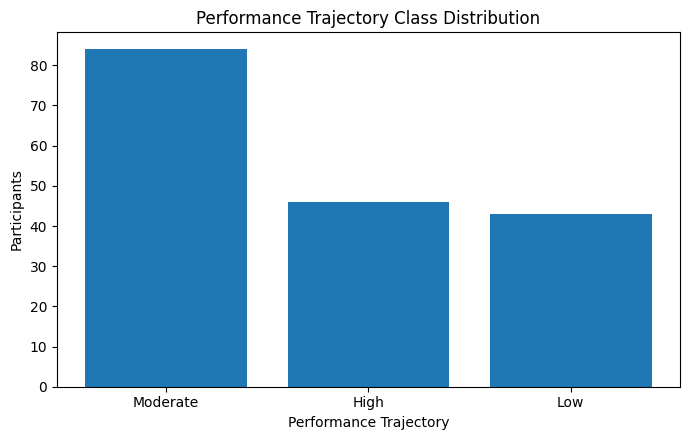

In [25]:
# 10.1 Plot class distribution

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(trajectory_distribution['Performance Trajectory'], trajectory_distribution['Participants'])
ax.set_title('Performance Trajectory Class Distribution')
ax.set_xlabel('Performance Trajectory')
ax.set_ylabel('Participants')
plt.tight_layout()
plt.show()

In [26]:
# 10.2 Target distribution by cohort

trajectory_by_cohort = pd.crosstab(trajectory_data['Cohort ID'], trajectory_data['Performance Trajectory'])
display(trajectory_by_cohort)

Performance Trajectory,High,Low,Moderate
Cohort ID,,,
AIB-2026-MEKAR-C1,6,5,15
CIMB-2026-MH-C1,7,13,5
MBSB-2025-C1,1,3,14
MIB-2025-C1,10,4,13
MIB-2025-C2,12,7,11
MIB-2025-C3,3,6,15
UNDP-2026-C1,7,5,11


In [27]:
# 10.3 Percentage distribution by cohort

trajectory_by_cohort_pct = pd.crosstab(trajectory_data['Cohort ID'], trajectory_data['Performance Trajectory'], normalize='index') * 100
display(trajectory_by_cohort_pct.round(1))

Performance Trajectory,High,Low,Moderate
Cohort ID,,,
AIB-2026-MEKAR-C1,23.1,19.2,57.7
CIMB-2026-MH-C1,28.0,52.0,20.0
MBSB-2025-C1,5.6,16.7,77.8
MIB-2025-C1,37.0,14.8,48.1
MIB-2025-C2,40.0,23.3,36.7
MIB-2025-C3,12.5,25.0,62.5
UNDP-2026-C1,30.4,21.7,47.8


## 11. Link the Target Back to the Participant Dataset

Only the target label is merged into `relationship_base`. S1–S3 themselves should not later be used as model predictors.

In [28]:
# 11. Create target linkage table

trajectory_target = trajectory_data[['Participant ID','Cohort ID','Performance Trajectory']].drop_duplicates('Participant ID')
print('Target participants:', trajectory_target['Participant ID'].nunique())
display(trajectory_target.head())

Target participants: 173


,Participant ID,Cohort ID,Performance Trajectory
0,2025_IBU-ACADEMY-MIB-C1-01,MIB-2025-C1,High
1,2025_IBU-ACADEMY-MIB-C1-02,MIB-2025-C1,High
3,2025_IBU-ACADEMY-MIB-C1-04,MIB-2025-C1,Moderate
4,2025_IBU-ACADEMY-MIB-C1-05,MIB-2025-C1,Moderate
5,2025_IBU-ACADEMY-MIB-C1-06,MIB-2025-C1,High


In [30]:
# 11.1 Merge target into relationship_base

relationship_base_with_target = (
    relationship_base.drop(columns=['Performance Trajectory'], errors='ignore')
    .merge(
        trajectory_target[['Participant ID','Performance Trajectory']],
        on='Participant ID',
        how='left',
        validate='one_to_one'
    )
)

print(relationship_base_with_target['Performance Trajectory'].value_counts(dropna=False))

Performance Trajectory
Moderate    84
High        46
Low         43
NaN         28
Name: count, dtype: int64


## 12. Save Notebook 02 Outputs

In [31]:
# 12. Save target outputs

TARGET_PATH = OUTPUT_DIR / 'trajectory_target.csv'
RELATIONSHIP_TARGET_PATH = OUTPUT_DIR / 'relationship_base_with_target.csv'
TARGET_AUDIT_PATH = OUTPUT_DIR / 'trajectory_target_audit.csv'

trajectory_target.to_csv(TARGET_PATH, index=False)
relationship_base_with_target.to_csv(RELATIONSHIP_TARGET_PATH, index=False)
trajectory_data[['Participant ID','Cohort ID','Sales Before Program','Sales Month 1','Sales Month 2','Sales Month 3','Performance Trajectory']].to_csv(TARGET_AUDIT_PATH, index=False)

print('Saved:')
print('-', TARGET_PATH)
print('-', RELATIONSHIP_TARGET_PATH)
print('-', TARGET_AUDIT_PATH)

Saved:
- /content/drive/MyDrive/24088950_MAI_Research/outputs/trajectory_target.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/relationship_base_with_target.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/trajectory_target_audit.csv


In [32]:
# 13. Final summary

print('NOTEBOOK 02 SUMMARY')
print()
print('Eligible cohorts:', len(eligible_cohorts))
print('Participants with valid target:', trajectory_target['Participant ID'].nunique() if 'trajectory_target' in globals() else 0)
if 'trajectory_distribution' in globals():
    display(trajectory_distribution)
print()
print('Next notebook: 03_Feature_Engineering.ipynb')

NOTEBOOK 02 SUMMARY

Eligible cohorts: 7
Participants with valid target: 173


,Performance Trajectory,Participants,Percentage
0,Moderate,84,48.55
1,High,46,26.59
2,Low,43,24.86



Next notebook: 03_Feature_Engineering.ipynb
